# 02 — Previsione di carico e fotovoltaico

Si prevedono le ore del giorno D+1 alla mezzanotte fra D e D+1, usando solo misure fino alla fine del giorno D. Il notebook legge i risultati di `python -m microgrid.forecast`.

Tre previsioni a confronto:

- **ingenua**: stessa ora di 7 giorni prima per il carico, stessa ora del giorno prima per il fotovoltaico;
- **LightGBM statico**: addestrato una sola volta, prima dell'inizio del periodo da prevedere;
- **LightGBM riaddestrato ogni 7 giorni**: stessi iperparametri, ma riaddestrato ogni settimana con tutte le misure disponibili fino a quel momento. È la previsione che il sistema userà.

Il meteo del giorno D+1 è quello reale, usato come se fosse una previsione: è una semplificazione ottimistica.

In [1]:
import json

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from microgrid.config import load_config, resolve_path
from microgrid.dataset import local_index
from microgrid.forecast import METRICS_FILE, PARAMS_FILE, load_forecasts
from microgrid.plotting import COLORS, TEXT_SECONDARY, apply_style

apply_style()
config = load_config()
results_dir = resolve_path(config["paths"]["results"])
forecasts = load_forecasts(config)
forecasts.index = local_index(forecasts.index, config)
test = forecasts[forecasts["split"] == "test"]
refit = f"LightGBM riaddestrato ogni {config['forecast']['refit_every_days']} giorni"
print(f"Validazione: {(forecasts['split'] == 'validation').sum()} ore   test: {len(test)} ore")

Validazione: 2952 ore   test: 3001 ore


## 1. Iperparametri

Scelti con una cross-validation a 4 finestre espandibili sui soli dati di addestramento: ogni finestra addestra su un periodo e valida sul periodo successivo. Si provano tutte le combinazioni della griglia in `config/default.yaml`.

In [2]:
chosen = json.loads((results_dir / PARAMS_FILE).read_text())
rows = []
for target, result in chosen.items():
    trials = pd.DataFrame([{**trial["params"], "cv_mae": trial["cv_mae"]} for trial in result["trials"]])
    rows.append({"grandezza": target, **result["params"], "alberi": result["rounds"],
                 "MAE in CV (kW)": round(result["cv_mae"], 3),
                 "MAE peggiore della griglia (kW)": round(trials["cv_mae"].max(), 3),
                 "combinazioni provate": len(trials)})
pd.DataFrame(rows).set_index("grandezza")

,num_leaves,min_child_samples,reg_lambda,alberi,MAE in CV (kW),MAE peggiore della griglia (kW),combinazioni provate
grandezza,,,,,,,
load_kw,7,50,10.0,255,3.275,3.427,18
pv_kw,7,100,10.0,187,5.198,5.411,18


**Cosa si vede**

- Per entrambe le grandezze vincono gli alberi più piccoli della griglia (7 foglie) con la regolarizzazione più forte: con poco più di un anno e mezzo di dati, i modelli semplici generalizzano meglio.
- La differenza fra la combinazione migliore e la peggiore è piccola (circa il 4%): il risultato dipende poco dagli iperparametri.

## 2. Metriche

MAE e RMSE in kW; il MAE normalizzato è il MAE diviso per la media dei valori reali. Le tre previsioni sono valutate sulle stesse ore.

In [3]:
table = pd.read_csv(results_dir / METRICS_FILE)
naive_mae = table[table["model"] == "ingenua"].set_index(["target", "split"])["mae"]
table["MAE vs ingenua"] = [
    f"{(row.mae / naive_mae[(row.target, row.split)] - 1):+.0%}" if row.model != "ingenua" else ""
    for row in table.itertuples()
]
table = table.rename(columns={"target": "grandezza", "split": "periodo", "model": "previsione", "hours": "ore",
                              "mae": "MAE", "rmse": "RMSE", "nmae": "MAE normalizzato"})
table.set_index(["grandezza", "periodo", "previsione"]).round(3)

ore    MAE    RMSE  \
grandezza periodo    previsione                                                 
load      validation ingenua                              2952  3.160   5.437   
                     LightGBM statico                     2952  2.400   3.853   
                     LightGBM riaddestrato ogni 7 giorni  2952  2.380   3.849   
          test       ingenua                              3001  3.343   5.633   
                     LightGBM statico                     3001  3.839   5.719   
                     LightGBM riaddestrato ogni 7 giorni  3001  3.460   5.054   
pv        validation ingenua                              2952  7.503  15.823   
                     LightGBM statico                     2952  4.597   9.235   
                     LightGBM riaddestrato ogni 7 giorni  2952  4.553   9.142   
          test       ingenua                              3001  5.788  14.093   
                     LightGBM statico                     3001  3.567   8.245   
                     LightGBM riaddestrato ogni 7 giorni  3001  3.528   8.161   

                                                          MAE normalizzato  \
grandezza periodo    previsione                                              
load      validation ingenua                                         0.606   
                     LightGBM statico                                0.461   
                     LightGBM riaddestrato ogni 7 giorni             0.457   
          test       ingenua                                         0.275   
                     LightGBM statico                                0.316   
                     LightGBM riaddestrato ogni 7 giorni             0.285   
pv        validation ingenua                                         0.440   
                     LightGBM statico                                0.269   
                     LightGBM riaddestrato ogni 7 giorni             0.267   
          test       ingenua                                         0.804   
                     LightGBM statico                                0.496   
                     LightGBM riaddestrato ogni 7 giorni             0.490   

                                                         MAE vs ingenua  
grandezza periodo    previsione                                          
load      validation ingenua                                             
                     LightGBM statico                              -24%  
                     LightGBM riaddestrato ogni 7 giorni           -25%  
          test       ingenua                                             
                     LightGBM statico                              +15%  
                     LightGBM riaddestrato ogni 7 giorni            +4%  
pv        validation ingenua                                             
                     LightGBM statico                              -39%  
                     LightGBM riaddestrato ogni 7 giorni           -39%  
          test       ingenua                                             
                     LightGBM statico                              -38%  
                     LightGBM riaddestrato ogni 7 giorni           -39%

**Cosa si vede**

- **Fotovoltaico.** Il modello riduce il MAE del 39% rispetto alla previsione ingenua, sia in validazione sia sul test. Riaddestrarlo cambia poco.
- **Carico, validazione (estate).** Il modello riduce il MAE del 25%.
- **Carico, test (autunno–inverno).** Il modello **non** batte la previsione ingenua sul MAE: +4% riaddestrato, +15% statico. È migliore solo sul RMSE (5,05 contro 5,63 kW), cioè commette meno errori grandi.
- In inverno il MAE normalizzato del fotovoltaico è alto (0,49) perché la produzione media è bassa; in kW l'errore è più piccolo che in estate.

## 3. Previsto e reale su una settimana del test set

Carico: MAE nella settimana 2.54 kW
Fotovoltaico: MAE nella settimana 4.05 kW


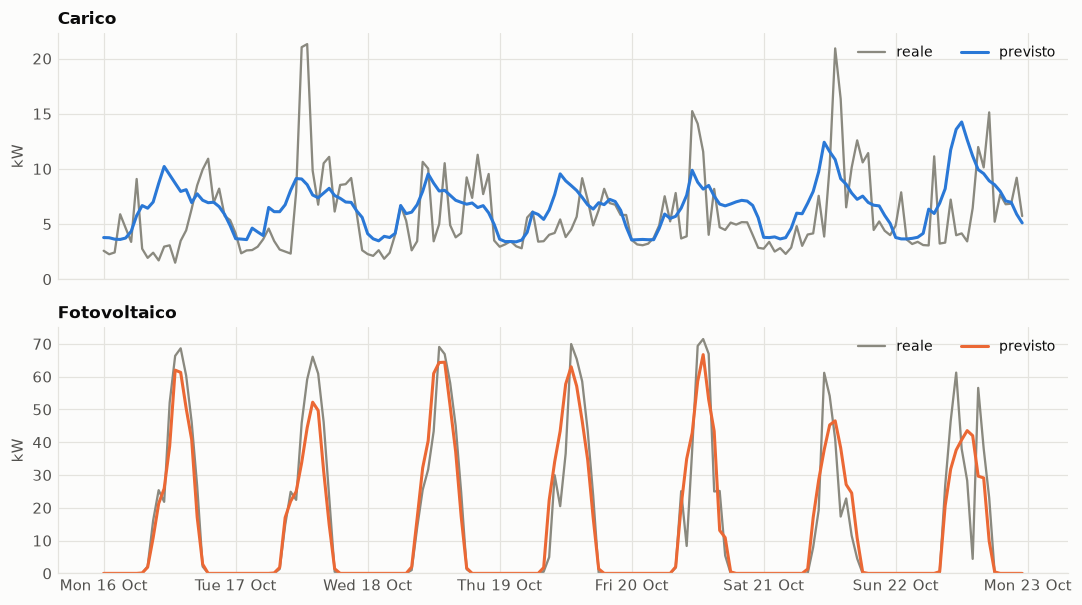

In [4]:
week = test.loc["2017-10-16":"2017-10-22"]
panels = [("load_kw", "load_forecast", "load", "Carico"), ("pv_kw", "pv_forecast", "pv", "Fotovoltaico")]
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
for ax, (actual, predicted, color, title) in zip(axes, panels):
    ax.plot(week.index, week[actual], color=COLORS["muted"], linewidth=1.5, label="reale")
    ax.plot(week.index, week[predicted], color=COLORS[color], label="previsto")
    ax.set_ylim(0, None)
    ax.set_ylabel("kW")
    ax.set_title(title)
    ax.legend(loc="upper right", ncols=2, fontsize=9)
    error = (week[predicted] - week[actual]).abs().mean()
    print(f"{title}: MAE nella settimana {error:.2f} kW")
axes[-1].xaxis.set_major_locator(mdates.DayLocator(tz=week.index.tz))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b", tz=week.index.tz))
fig.tight_layout()
plt.show()

**Cosa si vede**

- Il fotovoltaico previsto segue bene la forma della giornata; sbaglia nei giorni di nuvolosità variabile (sabato 21 e domenica 22), dove il meteo orario non coglie i passaggi di nuvole.
- Il carico previsto è una versione smussata di quello reale: il livello e l'andamento della giornata sono giusti, i picchi di una o due ore no. Con due sole abitazioni quei picchi dipendono da singoli apparecchi e non sono prevedibili il giorno prima.

## 4. Errore per ora del giorno

MAE sul test set per ora locale, previsione ingenua e modello riaddestrato.

Carico
utc_timestamp   0    1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23
ingenua        2.8  2.1  1.5  1.6  1.3  1.6  2.1  3.2  4.1  4.7  4.9  4.6  5.3  5.8  4.0  3.6  4.0  4.0  2.7  3.3  3.4  3.8  2.7  2.9
LightGBM       2.1  1.9  1.4  1.8  1.3  2.1  1.9  3.0  4.9  6.1  7.2  4.7  6.2  6.0  5.0  4.1  4.4  3.7  2.7  2.5  3.1  2.9  2.0  2.2
Fotovoltaico
utc_timestamp   0    1    2    3    4    5    6    7    8     9     10    11    12    13    14    15   16   17   18   19   20   21   22   23
ingenua        0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.9  10.2  15.1  22.7  24.6  22.4  18.9  14.9  6.1  2.0  0.3  0.0  0.0  0.0  0.0  0.0
LightGBM       0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.5   6.7   9.5  13.3  15.0  12.6  11.3   8.6  4.3  1.7  0.2  0.0  0.0  0.0  0.0  0.0


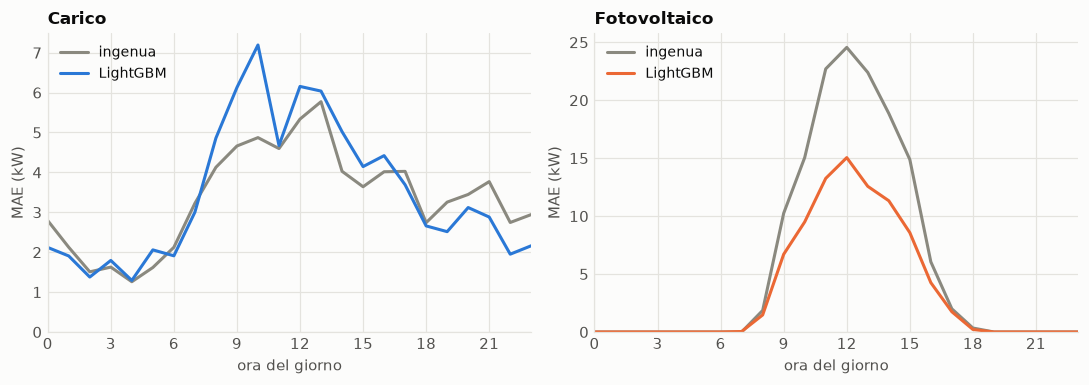

In [5]:
panels = [("load_kw", "load", "Carico"), ("pv_kw", "pv", "Fotovoltaico")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (actual, name, title) in zip(axes, panels):
    by_hour = pd.DataFrame({
        "ingenua": (test[f"{name}_naive"] - test[actual]).abs().groupby(test.index.hour).mean(),
        "LightGBM": (test[f"{name}_forecast"] - test[actual]).abs().groupby(test.index.hour).mean(),
    })
    ax.plot(by_hour.index, by_hour["ingenua"], color=COLORS["muted"], label="ingenua")
    ax.plot(by_hour.index, by_hour["LightGBM"], color=COLORS[name], label="LightGBM")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_ylim(0, None)
    ax.set_xlabel("ora del giorno")
    ax.set_ylabel("MAE (kW)")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=9)
    print(title)
    print(by_hour.round(1).T.to_string())
fig.tight_layout()
plt.show()

**Cosa si vede**

- **Fotovoltaico.** Il modello dimezza quasi l'errore della previsione ingenua nelle ore centrali (15 kW contro 25 kW a mezzogiorno).
- **Carico.** Il modello è migliore di notte e la sera, peggiore fra le 8 e le 14. Il massimo dell'errore è alle 10 (7,2 kW contro 4,9 kW).

## 5. Errore sul carico mese per mese

Il risultato sul carico cambia molto dentro il test set: conviene guardarlo per mese.

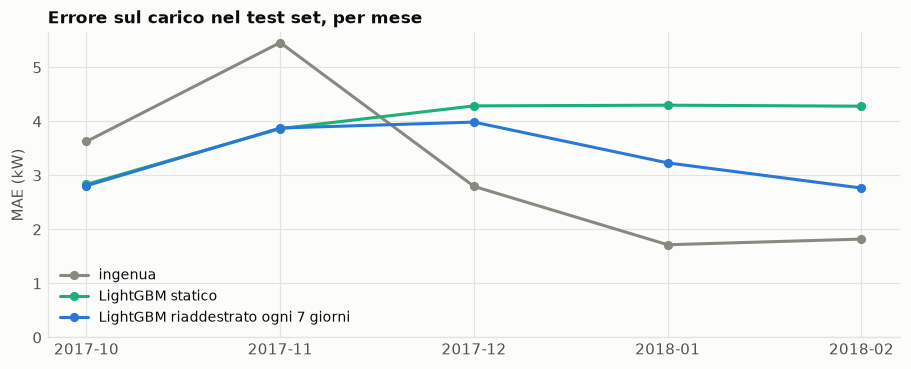

,ingenua,LightGBM statico,LightGBM riaddestrato ogni 7 giorni,carico medio
utc_timestamp,,,,
2017-10,3.63,2.83,2.81,6.85
2017-11,5.46,3.87,3.88,12.90
2017-12,2.80,4.29,3.99,14.55
2018-01,1.72,4.30,3.23,13.88
2018-02,1.82,4.28,2.77,14.78


In [6]:
month = test.index.tz_localize(None).to_period("M")
columns = {"ingenua": "load_naive", "LightGBM statico": "load_forecast_static", refit: "load_forecast"}
monthly = pd.DataFrame({name: (test[column] - test["load_kw"]).abs().groupby(month).mean()
                        for name, column in columns.items()})
monthly["carico medio"] = test["load_kw"].groupby(month).mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
positions = range(len(monthly))
styles = [("ingenua", COLORS["muted"]), ("LightGBM statico", COLORS["alt"]), (refit, COLORS["load"])]
for name, color in styles:
    ax.plot(positions, monthly[name], color=color, marker="o", markersize=5, label=name)
ax.set_xticks(positions, [str(period) for period in monthly.index])
ax.set_ylim(0, None)
ax.set_ylabel("MAE (kW)")
ax.set_title("Errore sul carico nel test set, per mese")
ax.legend(loc="lower left", fontsize=9)
plt.show()

monthly.round(2)

**Cosa si vede**

- A ottobre e novembre il modello batte la previsione ingenua di oltre il 20%.
- Da dicembre il rapporto si inverte. Nell'inverno 2017–18 il carico ha un andamento settimanale molto regolare, con un picco fra le 8 e le 10 che negli inverni precedenti non c'era: ripetere la settimana prima funziona benissimo (MAE 1,7 kW a gennaio), mentre il modello ha imparato da due anni in cui quell'abitudine non esisteva.
- Il riaddestramento settimanale recupera parte del ritardo (da 4,3 a 2,8 kW a febbraio), ma non abbastanza da raggiungere la previsione ingenua.
- Il modello statico non si adatta affatto: il suo errore resta a 4,3 kW per tre mesi.

## Conclusioni

- Il sistema userà il modello **riaddestrato ogni 7 giorni**, che è anche il migliore in validazione per entrambe le grandezze.
- **Avvertenza.** Il riaddestramento è stato introdotto dopo aver visto che il modello statico peggiorava sul test set. Non usa dati futuri, è una pratica operativa normale e gli iperparametri non sono stati modificati; resta però una scelta fatta conoscendo il risultato sul test.
- Sul fotovoltaico la previsione è nettamente migliore di quella ingenua.
- Sul carico, nel test set, è alla pari con quella ingenua: meglio sugli errori grandi, peggio sull'errore medio. La causa è un cambio di abitudini in una delle due abitazioni, non un difetto nei dati.
- Il meteo usato è quello reale: con previsioni meteo vere l'errore sul fotovoltaico sarebbe più alto.
- La simulazione dirà quanto di questo errore si traduce in costo: la colonna `load_naive` resta nel file delle previsioni per poter confrontare.